In [1]:
import pandas as pd

df = pd.read_csv(
    "scrdata_norte_nordeste_pessoa_fisica_baixa_renda.csv", sep=";", decimal=","
)  # pegue a base de dados "scrdata_norte_nordeste_pessoa_fisica_baixa_renda.csv" que esta localizada na task FC404-102
df.head()

,data_base,uf,segmento,cliente,cnae_ocupacao,porte,modalidade,submodalidade,origem,indexador,...,a_vencer_de_1081_ate_1800_dias,a_vencer_de_1801_ate_5400_dias,a_vencer_acima_de_5400_dias,carteira_a_vencer,vencido_de_15_ate_90_dias,vencido_acima_de_90_dias,carteira_vencida,carteira_ativa,carteira_inadimplencia,ativo_problematico
0,2026-01-31,AC,Banco,PF,Aposentado/pensionista,Até 1 salário mínimo,Adiantamentos a depositantes,Adiantamentos a depositantes,Sem destinação específica,Prefixado,...,0.00,0.00,0.0,245.09,0.00,20.46,20.46,265.55,20.46,20.46
1,2026-01-31,AC,Banco,PF,Aposentado/pensionista,Até 1 salário mínimo,Empréstimos,Capital de giro com teto rotativo,Sem destinação específica,Prefixado,...,0.00,0.00,0.0,0.00,827.71,0.00,827.71,827.71,0.00,827.71
2,2026-01-31,AC,Banco,PF,Aposentado/pensionista,Até 1 salário mínimo,Empréstimos,"Cartão de crédito - compra, fatura parcelada o...",Sem destinação específica,Prefixado,...,148482.46,78938.49,0.0,744648.25,1300.12,74514.95,75815.07,820463.32,74514.95,89980.31
3,2026-01-31,AC,Banco,PF,Aposentado/pensionista,Até 1 salário mínimo,Empréstimos,Cartão de crédito - não migrado,Sem destinação específica,Pós-fixado,...,2053.98,632.17,0.0,7098.20,304.59,9278.91,9583.50,16681.70,16681.70,16681.70
4,2026-01-31,AC,Banco,PF,Aposentado/pensionista,Até 1 salário mínimo,Empréstimos,Cartão de crédito - não migrado,Sem destinação específica,Prefixado,...,5103.32,1494.03,0.0,24335.07,22469.45,231343.18,253812.63,278147.70,231343.18,241008.92


In [7]:
print(df.shape)
print(df["data_base"].unique())
print(df["uf"].unique())

(182157, 25)
<DatetimeArray>
['2026-01-31 00:00:00', '2026-02-28 00:00:00', '2026-03-31 00:00:00',
 '2026-04-30 00:00:00', '2026-05-31 00:00:00', '2026-06-30 00:00:00',
 '2026-07-31 00:00:00']
Length: 7, dtype: datetime64[us]
<StringArray>
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'MA', 'PA', 'PB', 'PE', 'PI', 'RN', 'RO',
 'RR', 'SE', 'TO']
Length: 16, dtype: str


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182157 entries, 0 to 182156
Data columns (total 25 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   data_base                       182157 non-null  datetime64[us]
 1   uf                              182157 non-null  str           
 2   segmento                        182157 non-null  str           
 3   cliente                         182157 non-null  str           
 4   cnae_ocupacao                   182157 non-null  str           
 5   porte                           182157 non-null  str           
 6   modalidade                      182157 non-null  str           
 7   submodalidade                   182157 non-null  str           
 8   origem                          182157 non-null  str           
 9   indexador                       182157 non-null  str           
 10  numero_de_operacoes             182157 non-null  int64         
 11

In [16]:
df["data_base"] = pd.to_datetime(df["data_base"])

norte = [
    "AC",
    "AP",
    "AM",
    "PA",
    "RO",
    "RR",
    "TO",
]  # cria a lista de estados da região Norte

# cria uma nova coluna com as regiões norte e nordeste
df["regiao"] = df["uf"].apply(
    lambda uf: "Norte" if uf in norte else "Nordeste"
)  # faz if/else se a uf estiver na lista norte, se nao tiver ela é nordeste

print(df["uf"].unique())
print(df.columns.tolist())

<StringArray>
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'MA', 'PA', 'PB', 'PE', 'PI', 'RN', 'RO',
 'RR', 'SE', 'TO']
Length: 16, dtype: str
['data_base', 'uf', 'segmento', 'cliente', 'cnae_ocupacao', 'porte', 'modalidade', 'submodalidade', 'origem', 'indexador', 'numero_de_operacoes', 'a_vencer_ate_90_dias', 'a_vencer_de_91_ate_360_dias', 'a_vencer_de_361_ate_1080_dias', 'a_vencer_de_1081_ate_1800_dias', 'a_vencer_de_1801_ate_5400_dias', 'a_vencer_acima_de_5400_dias', 'carteira_a_vencer', 'vencido_de_15_ate_90_dias', 'vencido_acima_de_90_dias', 'carteira_vencida', 'carteira_ativa', 'carteira_inadimplencia', 'ativo_problematico', 'regiao']


In [19]:
# Soma carteira ativa e inadimplência por mês e estado
mensal = (
    df.groupby(["data_base", "regiao", "uf"])[
        ["carteira_ativa", "carteira_inadimplencia"]
    ]
    .sum()
    .reset_index()
)

# Calcula a taxa de inadimplência em % de cada mês
mensal["inadimplencia_pct"] = (
    mensal["carteira_inadimplencia"] / mensal["carteira_ativa"] * 100
)
# Tira a média das taxas dos meses, por estado
barras = mensal.groupby(["regiao", "uf"])[["inadimplencia_pct"]].mean()
# Mostra a tabela
barras

inadimplencia_pct
regiao   uf                   
Nordeste AL           8.218191
         BA           8.858922
         CE           7.597675
         MA           7.739307
         PB           6.312282
         PE           8.143237
         PI           7.612918
         RN           7.200018
         SE           7.726497
Norte    AC          10.387773
         AM          10.625608
         AP          11.252076
         PA           9.385941
         RO           8.585534
         RR          11.375306
         TO           9.846952

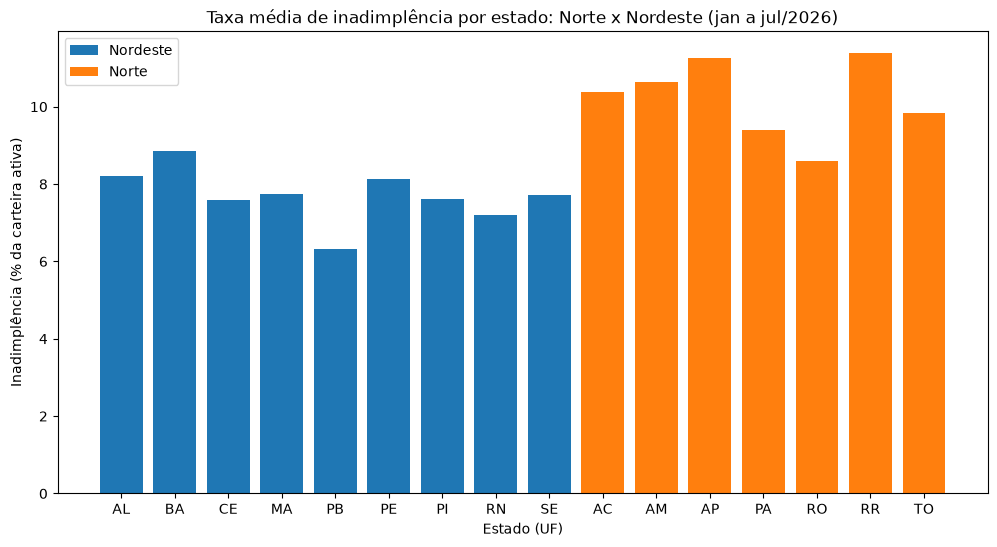

In [39]:
import matplotlib.pyplot as plt

dados = barras.reset_index()
norte_df = dados[dados["regiao"] == "Norte"]
nordeste_df = dados[dados["regiao"] == "Nordeste"]

plt.figure(figsize=(12, 6))
plt.bar(nordeste_df["uf"], nordeste_df["inadimplencia_pct"], label="Nordeste")
plt.bar(norte_df["uf"], norte_df["inadimplencia_pct"], label="Norte")
plt.title("Taxa média de inadimplência por estado: Norte x Nordeste (jan a jul/2026)")
plt.xlabel("Estado (UF)")
plt.ylabel("Inadimplência (% da carteira ativa)")
plt.legend()
plt.show()

In [40]:
# Soma carteira ativa e inadimplência por mês e região (14 linhas)
linhas = (
    df.groupby(["data_base", "regiao"])[["carteira_ativa", "carteira_inadimplencia"]]
    .sum()
    .reset_index()
)

# Calcula a taxa de inadimplência em % (inadimplência / carteira ativa * 100)
linhas["inadimplencia_pct"] = (
    linhas["carteira_inadimplencia"] / linhas["carteira_ativa"] * 100
)

# Mostra a tabela para conferir
linhas

,data_base,regiao,carteira_ativa,carteira_inadimplencia,inadimplencia_pct
0,2026-01-31,Nordeste,2.621800e+11,1.925797e+10,7.345324
1,2026-01-31,Norte,6.498950e+10,5.780966e+09,8.895230
2,2026-02-28,Nordeste,2.654687e+11,2.021410e+10,7.614496
3,2026-02-28,Norte,6.603415e+10,6.122586e+09,9.271847
4,2026-03-31,Nordeste,2.680612e+11,2.011345e+10,7.503304
5,2026-03-31,Norte,6.674813e+10,6.188246e+09,9.271041
6,2026-04-30,Nordeste,2.699261e+11,2.085487e+10,7.726141
7,2026-04-30,Norte,6.747179e+10,6.525659e+09,9.671684
8,2026-05-31,Nordeste,2.346005e+11,2.042343e+10,8.705624
9,2026-05-31,Norte,6.146997e+10,6.523315e+09,10.612197


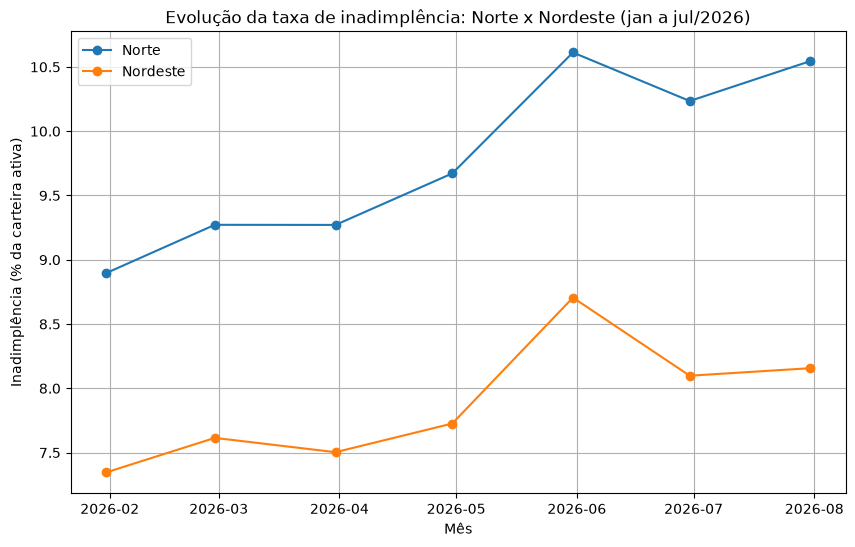

In [41]:
plt.figure(figsize=(10, 6))

for regiao in ["Norte", "Nordeste"]:
    parte = linhas[linhas["regiao"] == regiao]
    plt.plot(parte["data_base"], parte["inadimplencia_pct"], marker="o", label=regiao)

plt.title("Evolução da taxa de inadimplência: Norte x Nordeste (jan a jul/2026)")
plt.xlabel("Mês")
plt.ylabel("Inadimplência (% da carteira ativa)")
plt.legend()
plt.grid(True)
plt.show()

In [42]:
colunas = ["carteira_ativa", "carteira_inadimplencia", "ativo_problematico"]

evolucao = df.groupby(["data_base", "regiao"])[colunas].sum().reset_index()
evolucao[colunas] = evolucao[colunas] / 1e9
evolucao

,data_base,regiao,carteira_ativa,carteira_inadimplencia,ativo_problematico
0,2026-01-31,Nordeste,262.179968,19.257968,28.756108
1,2026-01-31,Norte,64.989499,5.780966,7.836856
2,2026-02-28,Nordeste,265.468697,20.214104,30.132547
3,2026-02-28,Norte,66.034154,6.122586,8.300073
4,2026-03-31,Nordeste,268.061239,20.113448,30.530239
5,2026-03-31,Norte,66.748131,6.188246,8.540139
6,2026-04-30,Nordeste,269.926119,20.854872,31.191317
7,2026-04-30,Norte,67.471795,6.525659,8.865029
8,2026-05-31,Nordeste,234.600451,20.423433,29.041410
9,2026-05-31,Norte,61.469975,6.523315,8.575324


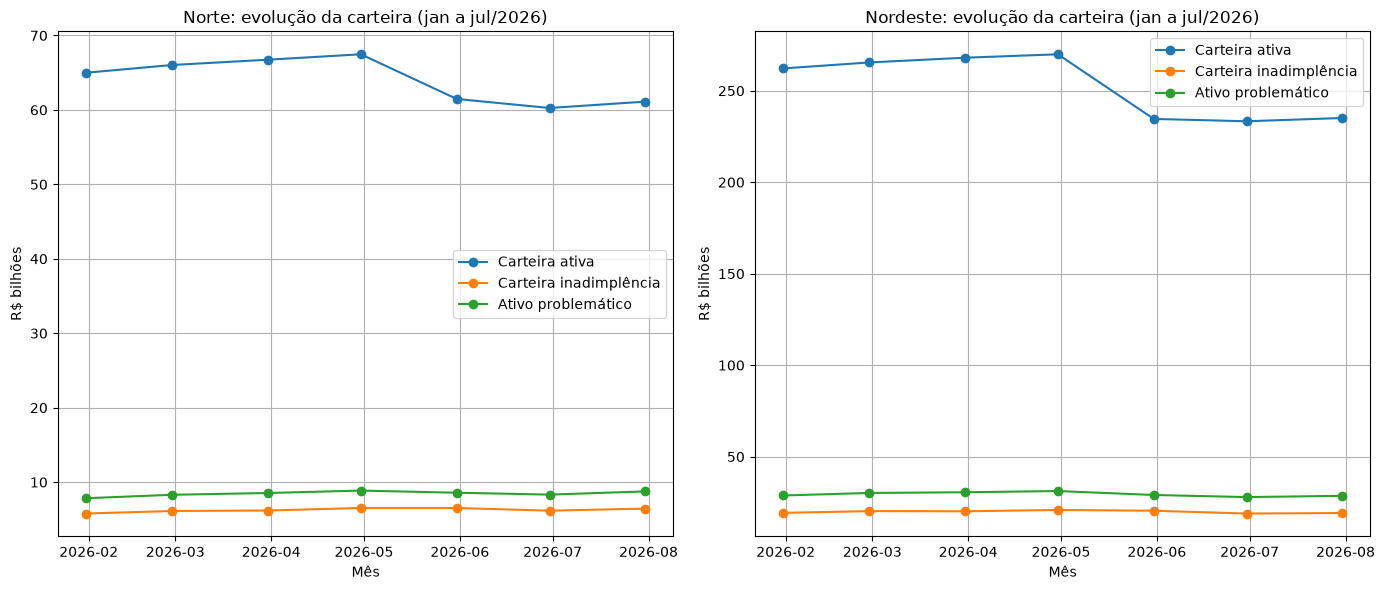

In [43]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 6))

for eixo, regiao in zip(eixos, ["Norte", "Nordeste"]):
    parte = evolucao[evolucao["regiao"] == regiao]
    eixo.plot(
        parte["data_base"], parte["carteira_ativa"], marker="o", label="Carteira ativa"
    )
    eixo.plot(
        parte["data_base"],
        parte["carteira_inadimplencia"],
        marker="o",
        label="Carteira inadimplência",
    )
    eixo.plot(
        parte["data_base"],
        parte["ativo_problematico"],
        marker="o",
        label="Ativo problemático",
    )
    eixo.set_title(f"{regiao}: evolução da carteira (jan a jul/2026)")
    eixo.set_xlabel("Mês")
    eixo.set_ylabel("R$ bilhões")
    eixo.legend()
    eixo.grid(True)

plt.tight_layout()
plt.show()